# Projeto de Previsão de Recrutamento (Status de Contratação)

Este projeto consiste em uma análise exploratória de dados (EDA) e no desenvolvimento de modelos de Machine Learning para prever o status de contratação (`status`) de candidatos com base em suas qualificações acadêmicas e experiência profissional.

---

## 📋 Visão Geral do Projeto

O conjunto de dados `Recrutamento.xlsx` contém informações sobre o histórico acadêmico, notas (provas de ensino fundamental, médio, graduação e MBA), especializações, experiência de trabalho anterior e o status final de contratação dos candidatos.

### Etapas Executadas no Notebook:
1. **Exploração de Dados (EDA):** Análise estatística e visualização de distribuições, correlações e detecção de *outliers* usando as bibliotecas `Seaborn` e `Plotly`.
2. **Tratamento de Dados:** Tratamento de valores nulos na coluna `salary` (preenchidos com `0` para candidatos não contratados).
3. **Engenharia de Recursos (Feature Engineering):**
   - Codificação de variáveis categóricas binárias (`gender`, `workex`, `specialisation`, `status`) utilizando `LabelEncoder`.
   - Criação de variáveis *dummy* para colunas categóricas com mais de duas categorias (`hsc_s` e `degree_t`).
4. **Modelagem:**
   - Divisão dos dados em treino e teste (80% treino / 20% teste) mantendo a proporção de classes (*stratify*).
   - Padronização das features utilizando `StandardScaler`.
   - **Modelo 1 (KNN Classifier):** Ajuste de hiperparâmetros (K) e avaliação (Acurácia: **~88.37%** para K=5).
   - **Modelo 2 (Linear SVM):** Implementação utilizando `Pipeline` e avaliação (Acurácia: **~86.04%**).

---

## 🛠️ Tecnologias e Bibliotecas Utilizadas

- **Python 3**
- **Pandas** (Manipulação e estruturação de dados)
- **Matplotlib & Seaborn** (Visualizações estáticas)
- **Plotly Express** (Visualizações interativas)
- **Missingno** (Visualização de dados ausentes)
- **Scikit-Learn** (Pré-processamento, divisão de dados e modelos de Machine Learning)

---

## 📈 Resultados Obtidos

- **Melhor Modelo:** KNN com $K = 5$ atingiu uma acurácia de aproximadamente **88.37%** na base de teste.
- **SVM Linear:** Atingiu uma acurácia de **86.04%**.

In [1]:
import pandas as pd

In [2]:
dados = pd.read_excel("Recrutamento.xlsx")

In [3]:
dados.head()

,sl_no,gender,ssc_p,ssc_b,hsc_p,hsc_b,hsc_s,degree_p,degree_t,workex,etest_p,specialisation,mba_p,status,salary
0,1,M,67.00,Others,91.00,Others,Commerce,58.00,Sci&Tech,No,55.0,Mkt&HR,58.80,Yes,270000.0
1,2,M,79.33,Central,78.33,Others,Science,77.48,Sci&Tech,Yes,86.5,Mkt&Fin,66.28,Yes,200000.0
2,3,M,65.00,Central,68.00,Central,Arts,64.00,Comm&Mgmt,No,75.0,Mkt&Fin,57.80,Yes,250000.0
3,4,M,56.00,Central,52.00,Central,Science,52.00,Sci&Tech,No,66.0,Mkt&HR,59.43,No,NaN
4,5,M,85.80,Central,73.60,Central,Commerce,73.30,Comm&Mgmt,No,96.8,Mkt&Fin,55.50,Yes,425000.0


In [4]:
dados.shape


(215, 15)

In [5]:
set(dados.status)

{'No', 'Yes'}

In [6]:
dados.describe()

,sl_no,ssc_p,hsc_p,degree_p,etest_p,mba_p,salary
count,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,148.000000
mean,108.000000,67.303395,66.333163,66.370186,72.100558,62.278186,288655.405405
std,62.209324,10.827205,10.897509,7.358743,13.275956,5.833385,93457.452420
min,1.000000,40.890000,37.000000,50.000000,50.000000,51.210000,200000.000000
25%,54.500000,60.600000,60.900000,61.000000,60.000000,57.945000,240000.000000
50%,108.000000,67.000000,65.000000,66.000000,71.000000,62.000000,265000.000000
75%,161.500000,75.700000,73.000000,72.000000,83.500000,66.255000,300000.000000
max,215.000000,89.400000,97.700000,91.000000,98.000000,77.890000,940000.000000


In [7]:
dados.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 215 entries, 0 to 214
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   sl_no           215 non-null    int64  
 1   gender          215 non-null    object 
 2   ssc_p           215 non-null    float64
 3   ssc_b           215 non-null    object 
 4   hsc_p           215 non-null    float64
 5   hsc_b           215 non-null    object 
 6   hsc_s           215 non-null    object 
 7   degree_p        215 non-null    float64
 8   degree_t        215 non-null    object 
 9   workex          215 non-null    object 
 10  etest_p         215 non-null    float64
 11  specialisation  215 non-null    object 
 12  mba_p           215 non-null    float64
 13  status          215 non-null    object 
 14  salary          148 non-null    float64
dtypes: float64(6), int64(1), object(8)
memory usage: 25.3+ KB


In [8]:
import missingno as msno #visualizar valores nulos de forma visual

<Axes: >

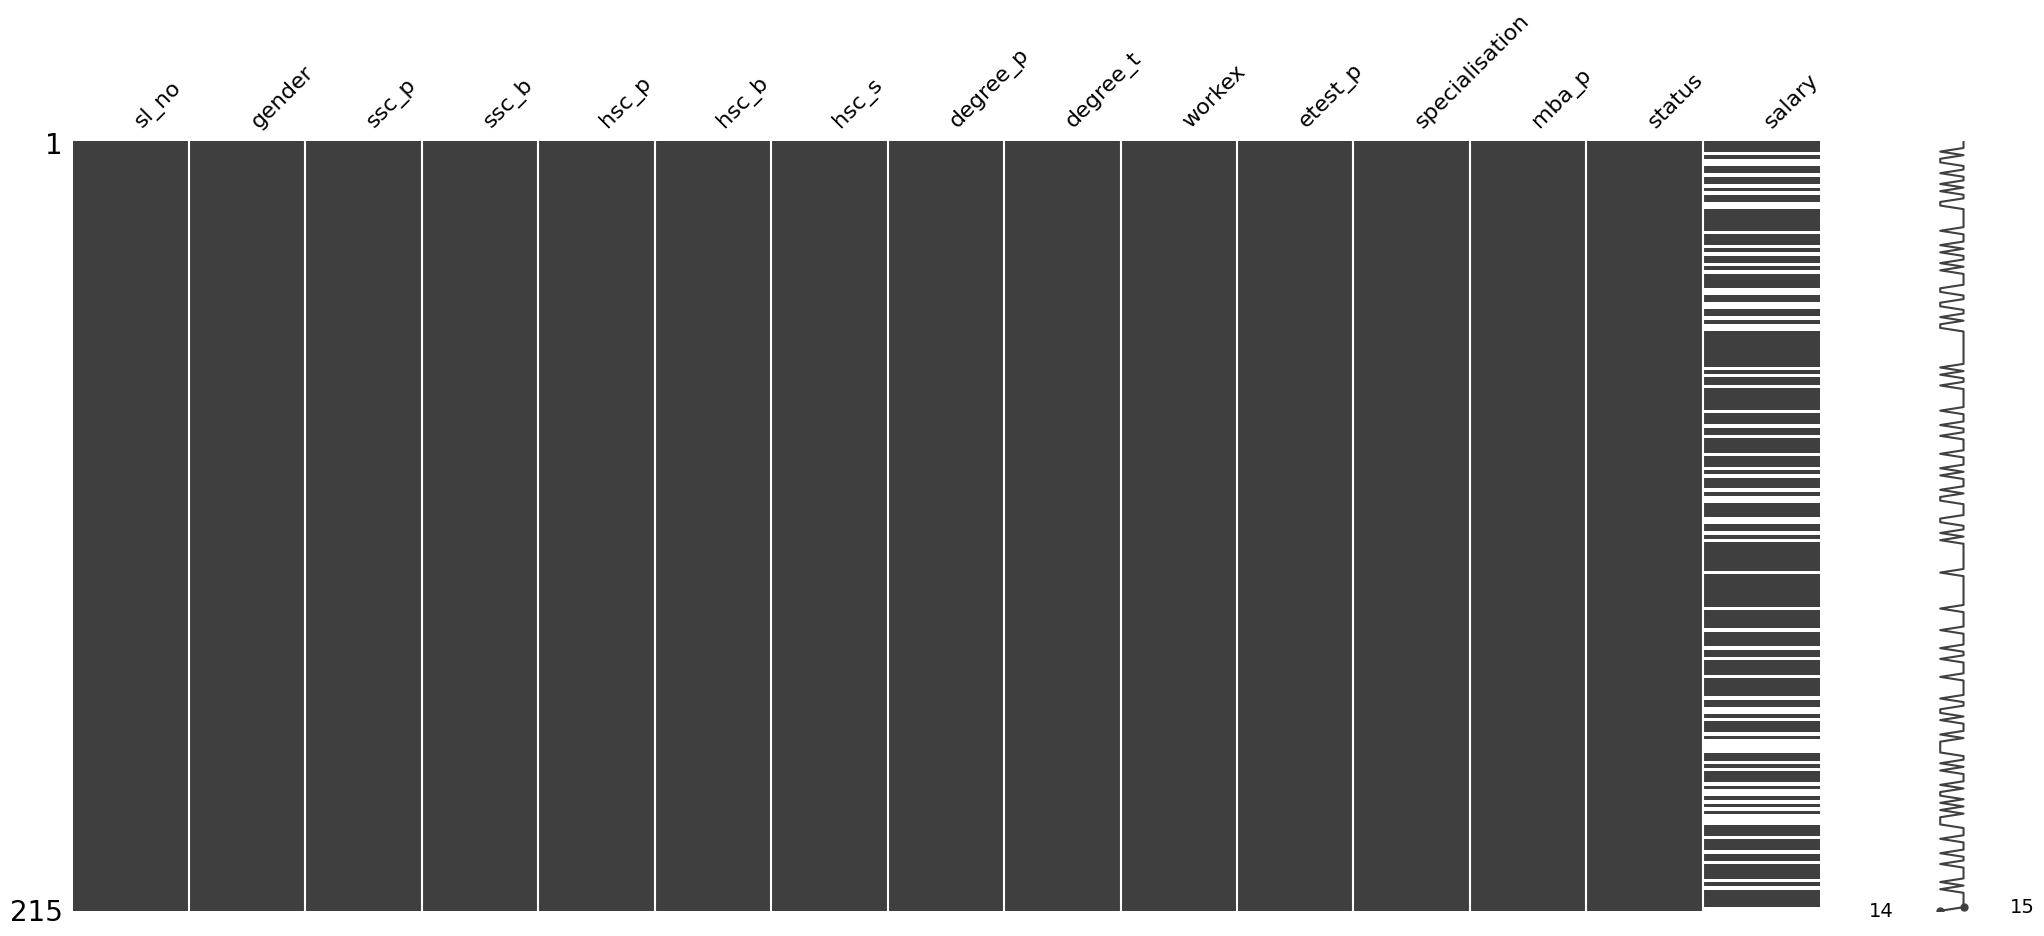

In [9]:
msno.matrix(dados)

In [10]:
dados.isnull().sum()

,0
sl_no,0
gender,0
ssc_p,0
ssc_b,0
hsc_p,0
hsc_b,0
hsc_s,0
degree_p,0
degree_t,0
workex,0


sálario possui 67 pessoas com valores nulos

In [11]:
import seaborn as sb

/tmp/ipykernel_4999/2309832914.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sb.boxplot(x="status", y="salary", data=dados, palette="hls")


<Axes: xlabel='status', ylabel='salary'>

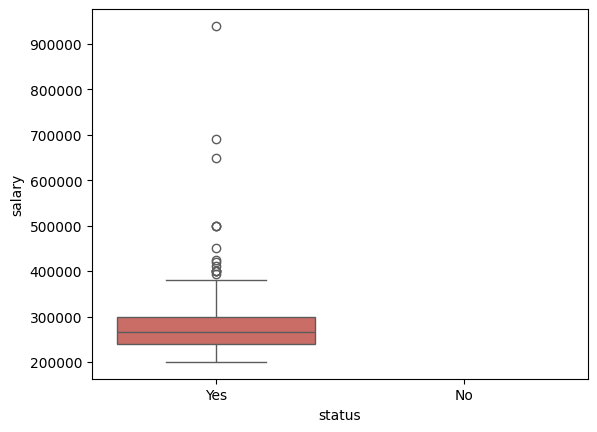

In [12]:
sb.boxplot(x="status", y="salary", data=dados, palette="hls")

In [13]:
dados["salary"].fillna(value=0, inplace=True) # fazer tratativa dos nulos na coluna "salary". (value 0: serve para trocar os nulos por zero e o inplace = true serve para fazer a mudança de imediato)

/tmp/ipykernel_4999/1298767103.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  dados["salary"].fillna(value=0, inplace=True) # fazer tratativa dos nulos na coluna "salary". (value 0: serve para trocar os nulos por zero e o inplace = true serve para fazer a mudança de imediato)


In [14]:
dados.isnull().sum()

,0
sl_no,0
gender,0
ssc_p,0
ssc_b,0
hsc_p,0
hsc_b,0
hsc_s,0
degree_p,0
degree_t,0
workex,0


<Axes: xlabel='hsc_p'>

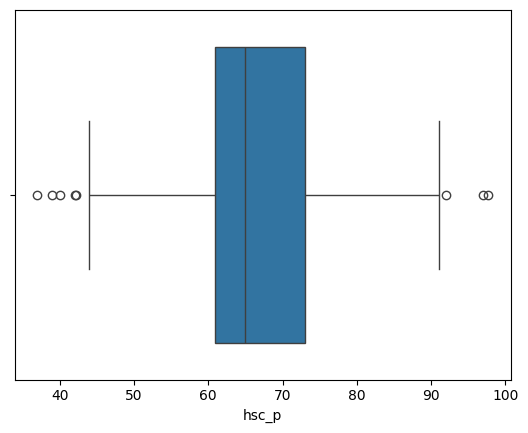

In [15]:
sb.boxplot(x=dados["hsc_p"])

As bolinhas brancas se cham "outliers" que são dados nas extremidades (tanto para menos quanto para mais)

<Axes: xlabel='hsc_p', ylabel='Count'>

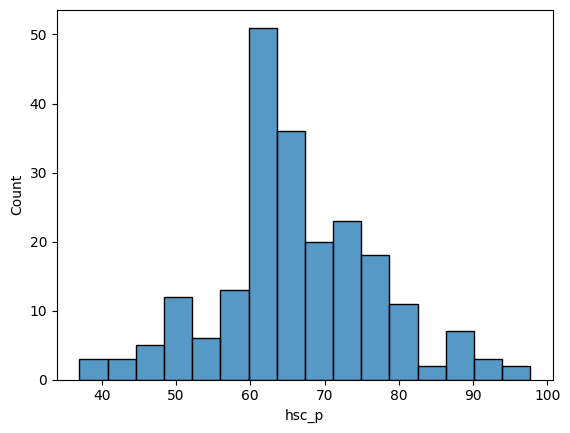

In [16]:
sb.histplot(data=dados, x="hsc_p")

<Axes: xlabel='degree_p'>

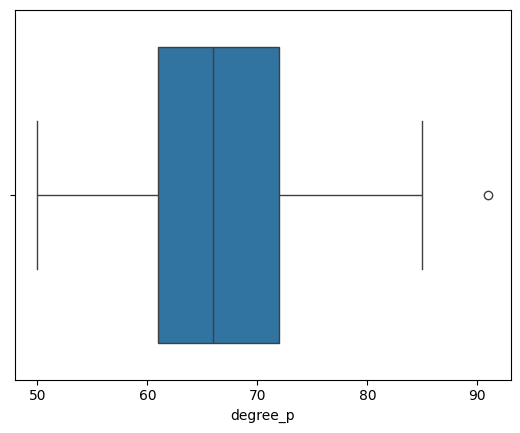

In [17]:
sb.boxplot(x=dados["degree_p"])

<Axes: xlabel='degree_p', ylabel='Count'>

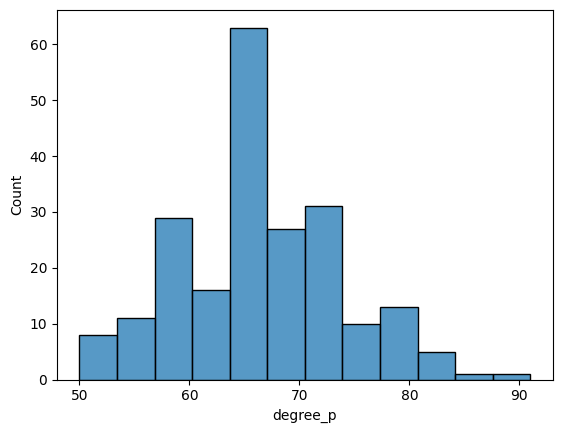

In [18]:
sb.histplot(data=dados, x="degree_p")

<Axes: xlabel='etest_p'>

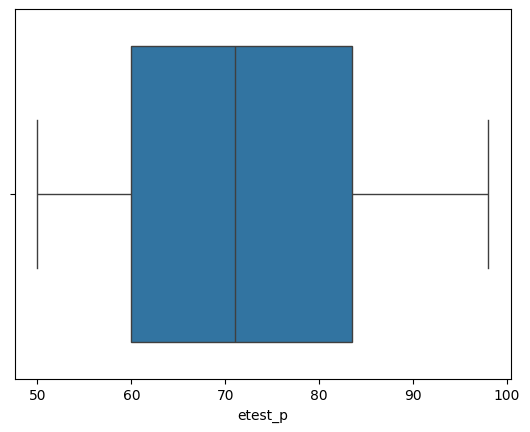

In [19]:
sb.boxplot(x=dados["etest_p"]) #nenhum outlier nas extremidades

<Axes: xlabel='etest_p', ylabel='Count'>

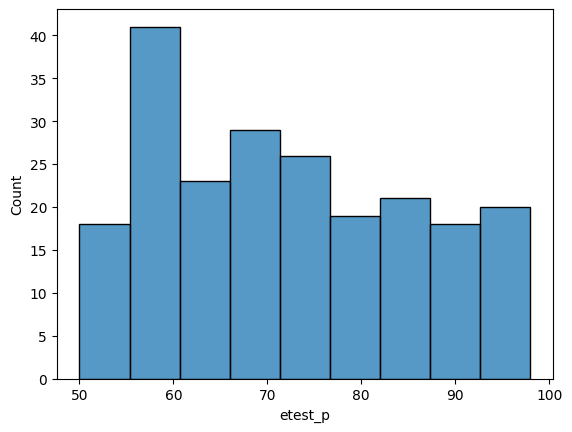

In [20]:
sb.histplot(data=dados, x="etest_p")

<Axes: xlabel='mba_p'>

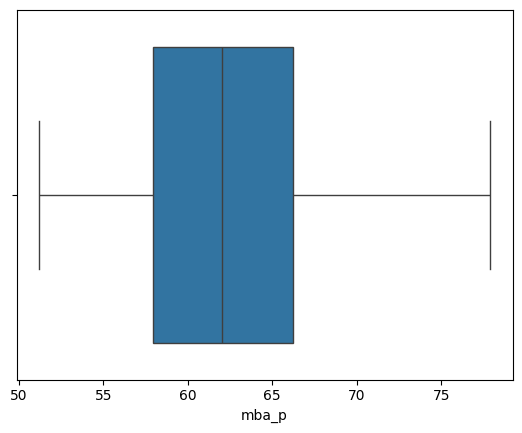

In [21]:
sb.boxplot(x=dados["mba_p"]) #nenhum outlier nas extremidades

<Axes: xlabel='salary'>

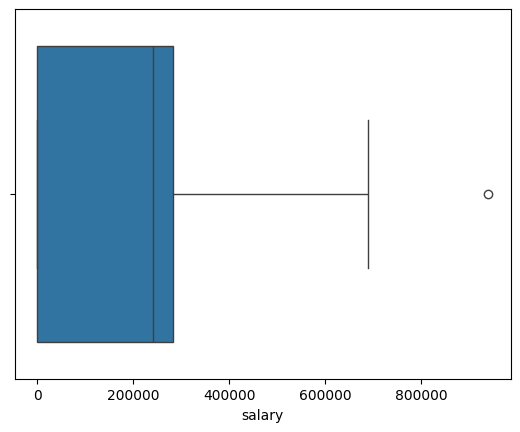

In [22]:
sb.boxplot(x=dados["salary"])

<Axes: xlabel='salary', ylabel='Count'>

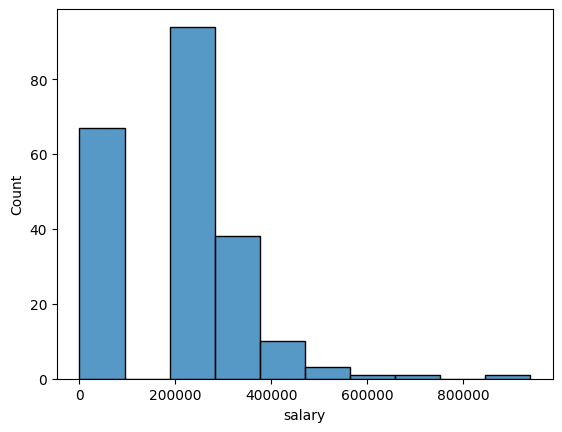

In [23]:
sb.histplot(data=dados, x="salary")

[Text(36.5, 0.5, 'mba_p')]

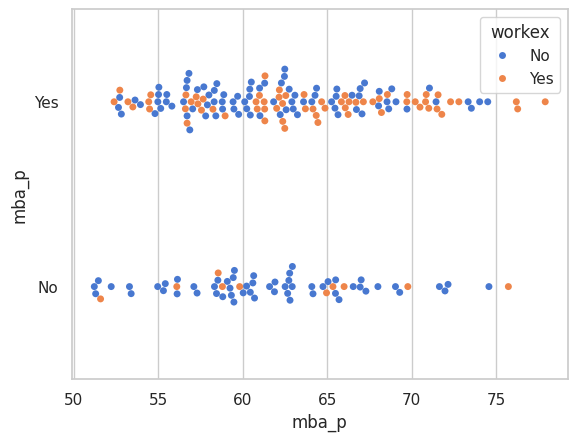

In [24]:
sb.set_theme(style="whitegrid", palette="muted")
ax=sb.swarmplot(data=dados, x="mba_p", y="status", hue="workex")
ax.set(ylabel="mba_p")

In [25]:
! pip install plotly_express

In [26]:
import plotly_express as px

In [27]:
px.violin(dados, y="salary", x="specialisation", color = "gender", box = True, points="all")

In [28]:
import matplotlib.pyplot as plt


<Axes: >

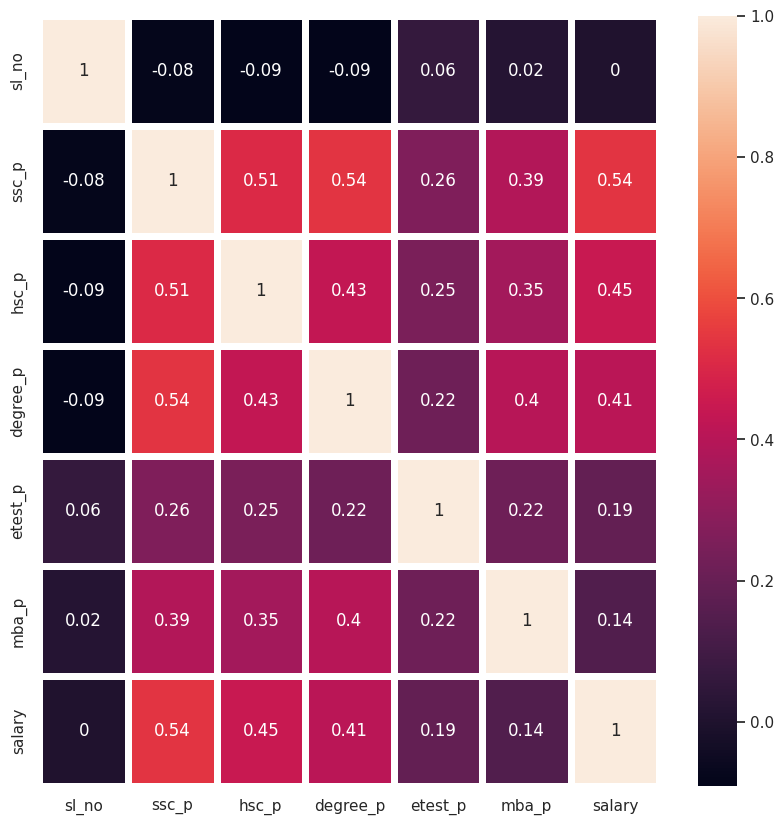

In [29]:
correlation_matriz = dados.corr(numeric_only=True).round(2)

fig, ax = plt.subplots(figsize=(10,10))
sb.heatmap(data = correlation_matriz, annot = True, linewidths=5, ax=ax)

In [30]:
from sklearn.preprocessing import LabelEncoder

In [31]:
dados.head()

,sl_no,gender,ssc_p,ssc_b,hsc_p,hsc_b,hsc_s,degree_p,degree_t,workex,etest_p,specialisation,mba_p,status,salary
0,1,M,67.00,Others,91.00,Others,Commerce,58.00,Sci&Tech,No,55.0,Mkt&HR,58.80,Yes,270000.0
1,2,M,79.33,Central,78.33,Others,Science,77.48,Sci&Tech,Yes,86.5,Mkt&Fin,66.28,Yes,200000.0
2,3,M,65.00,Central,68.00,Central,Arts,64.00,Comm&Mgmt,No,75.0,Mkt&Fin,57.80,Yes,250000.0
3,4,M,56.00,Central,52.00,Central,Science,52.00,Sci&Tech,No,66.0,Mkt&HR,59.43,No,0.0
4,5,M,85.80,Central,73.60,Central,Commerce,73.30,Comm&Mgmt,No,96.8,Mkt&Fin,55.50,Yes,425000.0


In [32]:
colunas = ["gender", "workex", "specialisation", "status"]

for coluna in colunas:
    le = LabelEncoder()
    dados[coluna] = le.fit_transform(dados[coluna])

In [33]:
dados.head()

,sl_no,gender,ssc_p,ssc_b,hsc_p,hsc_b,hsc_s,degree_p,degree_t,workex,etest_p,specialisation,mba_p,status,salary
0,1,1,67.00,Others,91.00,Others,Commerce,58.00,Sci&Tech,0,55.0,1,58.80,1,270000.0
1,2,1,79.33,Central,78.33,Others,Science,77.48,Sci&Tech,1,86.5,0,66.28,1,200000.0
2,3,1,65.00,Central,68.00,Central,Arts,64.00,Comm&Mgmt,0,75.0,0,57.80,1,250000.0
3,4,1,56.00,Central,52.00,Central,Science,52.00,Sci&Tech,0,66.0,1,59.43,0,0.0
4,5,1,85.80,Central,73.60,Central,Commerce,73.30,Comm&Mgmt,0,96.8,0,55.50,1,425000.0


In [34]:
dummy_hsc_s = pd.get_dummies(dados["hsc_s"], prefix="dummy")
dummy_degree_t = pd.get_dummies(dados["degree_t"], prefix="dummy")

dados_dummy = pd.concat([dados, dummy_hsc_s, dummy_degree_t], axis=1)

In [35]:
dados_dummy.head(2)

,sl_no,gender,ssc_p,ssc_b,hsc_p,hsc_b,hsc_s,degree_p,degree_t,workex,...,specialisation,mba_p,status,salary,dummy_Arts,dummy_Commerce,dummy_Science,dummy_Comm&Mgmt,dummy_Others,dummy_Sci&Tech
0,1,1,67.00,Others,91.00,Others,Commerce,58.00,Sci&Tech,0,...,1,58.80,1,270000.0,False,True,False,False,False,True
1,2,1,79.33,Central,78.33,Others,Science,77.48,Sci&Tech,1,...,0,66.28,1,200000.0,False,False,True,False,False,True


In [36]:
dados_dummy.drop(["hsc_s", "degree_t", "salary"], axis=1, inplace=True)

In [37]:
dados_dummy.head(2)

,sl_no,gender,ssc_p,ssc_b,hsc_p,hsc_b,degree_p,workex,etest_p,specialisation,mba_p,status,dummy_Arts,dummy_Commerce,dummy_Science,dummy_Comm&Mgmt,dummy_Others,dummy_Sci&Tech
0,1,1,67.00,Others,91.00,Others,58.00,0,55.0,1,58.80,1,False,True,False,False,False,True
1,2,1,79.33,Central,78.33,Others,77.48,1,86.5,0,66.28,1,False,False,True,False,False,True


<Axes: >

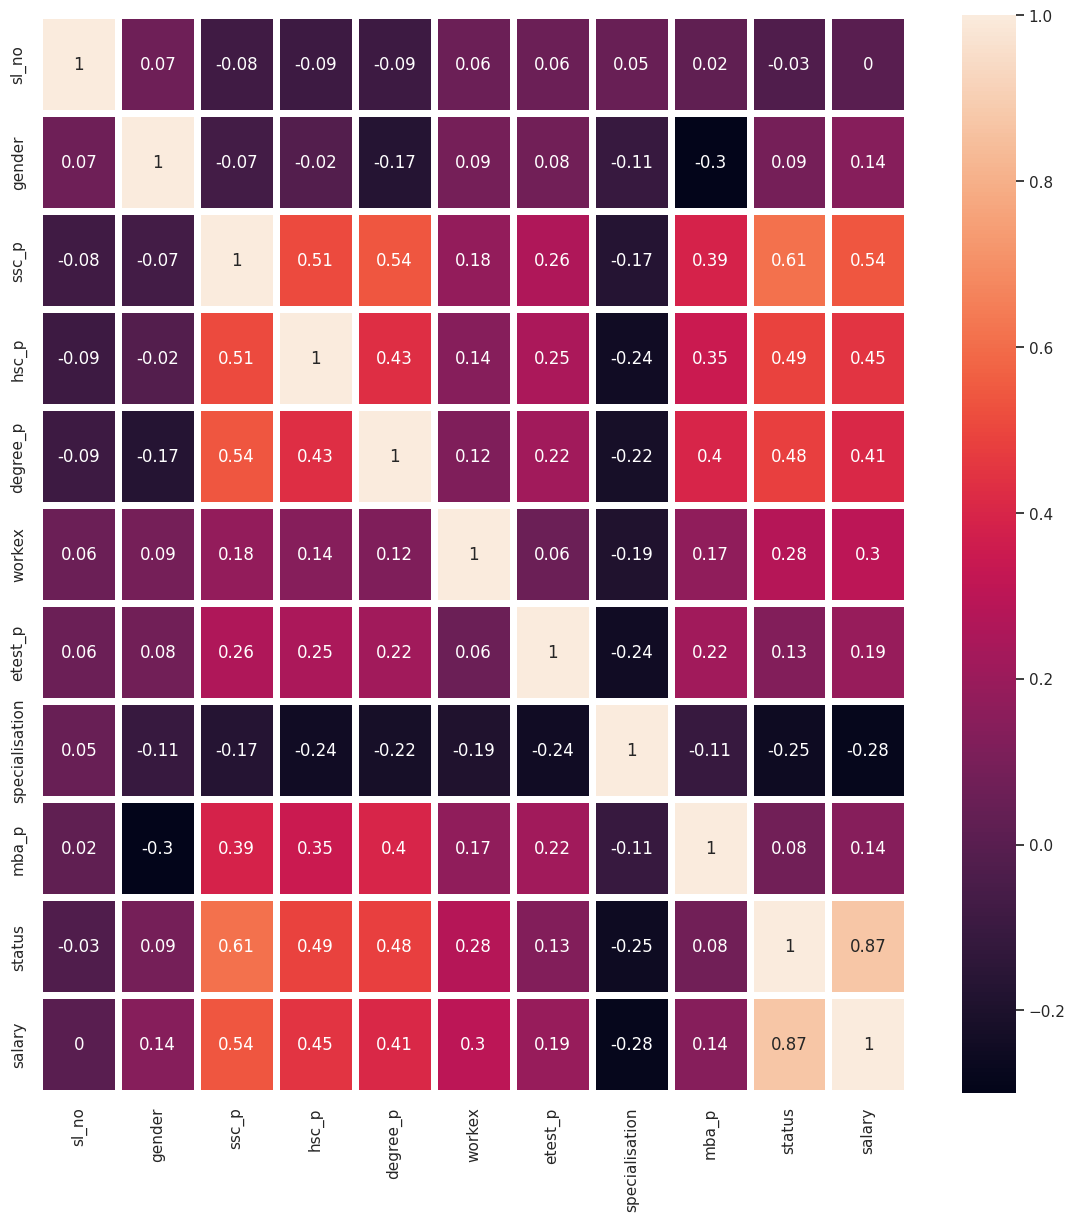

In [38]:
correlation_matriz = dados.corr(numeric_only=True).round(2)

fig, ax = plt.subplots(figsize=(14,14))
sb.heatmap(data = correlation_matriz, annot = True, linewidths=5, ax=ax)

In [39]:
x = dados_dummy[["ssc_p", "hsc_p", "degree_p", "workex", "mba_p"]]
y = dados_dummy["status"]

In [40]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

In [41]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, stratify=y, random_state=7)

In [42]:
x_train.shape

(172, 5)

In [43]:
x_test.shape

(43, 5)

In [44]:
x


,ssc_p,hsc_p,degree_p,workex,mba_p
0,67.00,91.00,58.00,0,58.80
1,79.33,78.33,77.48,1,66.28
2,65.00,68.00,64.00,0,57.80
3,56.00,52.00,52.00,0,59.43
4,85.80,73.60,73.30,0,55.50
...,...,...,...,...,...
210,80.60,82.00,77.60,0,74.49
211,58.00,60.00,72.00,0,53.62
212,67.00,67.00,73.00,1,69.72
213,74.00,66.00,58.00,0,60.23


In [45]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

In [46]:
scaler = StandardScaler()
scaler.fit(x_train) #aplicando o modelo fit (standard) em uma coluna - #x_train (base de treino)
x_train_scaled = scaler.transform(x_train) #transform serve para fazer uma padronização nos dados tanto no treino quanto no teste
x_test_scaled = scaler.transform(x_test)

In [47]:
x_train_scaled

array([[-1.92672757, -0.66933853, -0.31559155, -0.70402569, -0.11827471],
       [ 0.26708378, -0.33015908, -0.72064899, -0.70402569,  1.18141841],
       [-0.89983715, -0.57243011,  0.76456162, -0.70402569, -1.50694011],
       [ 1.06059001,  0.97810451,  2.51981052, -0.70402569,  1.18665207],
       [-1.4599592 , -1.54151426, -0.72064899, -0.70402569, -0.6521084 ],
       [ 0.30349171,  0.58853269, -0.09956092, -0.70402569,  1.63500259],
       [ 0.50046796, -0.76624694, -1.39574473, -0.70402569, -1.67790646],
       [ 1.80741941, -0.08788804,  1.97973393,  1.42040271,  1.83562636],
       [-0.05965408, -0.28170487, -0.31559155, -0.70402569, -0.06768263],
       [-0.43306878, -0.37861329, -0.18057241, -0.70402569, -0.27354006],
       [-0.43306878,  0.00902037, -0.31559155, -0.70402569,  0.31786392],
       [-0.52642246, -0.54045034, -0.28723753, -0.70402569, -0.39042522],
       [-1.55331288, -2.12296474, -1.26072558, -0.70402569, -1.88550845],
       [-0.7131298 , -0.28170487, -1.3

In [48]:
import numpy as np

In [49]:
error = []

for i in range(1, 10):
    knn = KNeighborsClassifier(n_neighbors=i)
    knn.fit(x_train_scaled, y_train)
    pred_i = knn.predict(x_test_scaled)
    error.append(np.mean(pred_i != y_test))

Text(0, 0.5, 'Erro médio')

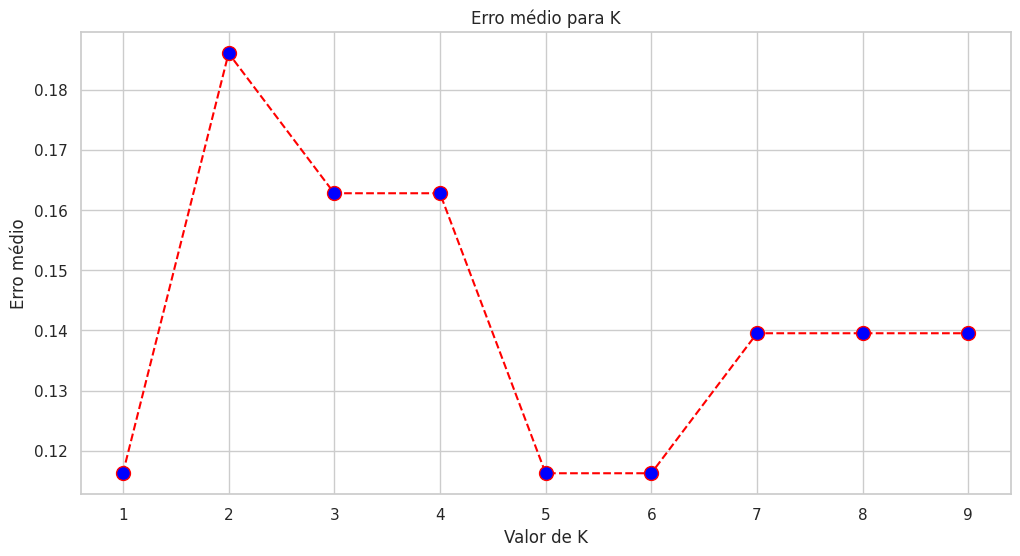

In [50]:
plt.figure(figsize=(12, 6))
plt.plot(range(1, 10), error, color="red", linestyle="dashed", marker="o", markerfacecolor="blue", markersize=10)
plt.title("Erro médio para K")
plt.xlabel("Valor de K")
plt.ylabel("Erro médio")

In [51]:
modelo_classificador = KNeighborsClassifier(n_neighbors=5)
modelo_classificador.fit(x_train_scaled, y_train)

KNeighborsClassifier()

In [52]:
y_predito = modelo_classificador.predict(x_test_scaled)

In [53]:
y_predito

array([1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1])

In [54]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [55]:
print(accuracy_score(y_test, y_predito))

0.8837209302325582


In [56]:
from sklearn.svm import LinearSVC

In [57]:
from sklearn.pipeline import Pipeline

In [58]:
svm = Pipeline(
    [
        ("linear_svc", LinearSVC(C=1))
    ]
)


In [59]:
svm.fit(x_train_scaled, y_train)

Pipeline(steps=[('linear_svc', LinearSVC(C=1))])

In [60]:
y_predito_svm = svm.predict(x_test_scaled)

In [61]:
print(accuracy_score(y_test, y_predito_svm))

0.8604651162790697
